<center>
<h1> TP-Projet d'optimisation numérique </h1>
<h1> Algorithme des régions de confiance </h1>
</center>

# Régions de confiance avec Pas de Cauchy 

## Implémentation 

1. Coder l'algorithme du pas de Cauchy dans le fichier `src/cauchy.jl`). La spécification de cet algorithme est donnée dans le fichier.
2. Ecrire des tests exhaustifs (qui testent tous les cas de figure possibles) pour votre algorithme du pas de Cauchy. Vous remplirez pour cela le fichier `test/tester_cauchy.jl` sur le modèle des autres fichiers de tests et vous exécuterez dans la cellule de code ci-après ces tests.

Les sept cas suivants doivent être testés :
1.	Gradient est presque nul: le pas doit être nul: $\|g \| < \epsilon \quad \Rightarrow \quad s = 0.$
2.	Cas SPD non saturé: $g^\top H g > 0$ et le pas reste à l’intérieur de la région de confiance: $s = -\frac{|g|^2}{g^\top H g} g, \qquad |s| < \Delta.$
3.	Cas SPD saturé: $g^\top H g > 0$ mais le pas est trop grand et doit être ramené sur la frontière: $ |s| = \Delta, \qquad s = -\frac{\Delta}{|g|} g.$
4.	Hessienne indéfinie avec $g^\top H g > 0$ et le rayon $\Delta$ est suffisamment grand pour que le pas reste à l’intérieur de la région.
5.	Hessienne indéfinie avec $g^\top H g > 0$ et le rayon $\Delta$ est trop petit, le pas doit saturer la frontière: $ s = -\frac{\Delta}{|g|} g, \qquad |s| = \Delta.$
6.	Hessienne non définie positive avec $g^\top H g < 0$: le pas doit être saturé (le modèle quadratique est non borné le long de $-g$): $s = -\frac{\Delta}{|g|}, g.$
7.	Cas dégénéré: $g^\top H g = 0$, donc le pas doit être saturé (le modèle est linéaire le long de $-g$): $s = -\frac{\Delta}{|g|}, g.$

In [50]:
include("../src/cauchy.jl")         # votre algorithme
include("../test/tester_cauchy.jl") # la fonction pour tester votre algorithme

#
tester_cauchy(cauchy); # tester l'algorithme

Test Summary: | Pass  Total  Time
Pas de Cauchy |   10     10  0.0s


3. Coder l'algorithme des régions de confiance (fichier `src/regions_de_confiance.jl`). Sa spécification est donnée dans le fichier.
4. Vérifier que les tests ci-dessous passent.

In [71]:
include("../src/regions_de_confiance.jl")
include("../test/tester_rc_cauchy.jl")

#
afficher = true # si true, alors affiche les résultats des algorithmes

#
tester_rc_cauchy(regions_de_confiance, afficher);

Affichage des résultats des algorithmes : true

-------------------------------------------------------------------------
Résultats de : RC et cauchy appliqué à f1:
  * x0       = [1, 0, 0]
  * x_sol    = [1.0000065049853921, 1.000000873235793, 0.9999952414861938]
  * f(x_sol) = 7.71589405988668e-11
  * nb_iters = 33
  * flag     = 2
  * solution = [1, 1, 1]
-------------------------------------------------------------------------
Résultats de : RC et cauchy appliqué à f1:
  * x0       = [10.0, 3.0, -2.2]
  * x_sol    = [1.000003643199092, 0.9999997146801121, 0.9999957861612833]
  * f(x_sol) = 3.233185493810428e-11
  * nb_iters = 34
  * flag     = 2
  * solution = [1, 1, 1]
-------------------------------------------------------------------------
Résultats de : RC et cauchy appliqué à f2:
  * x0       = [-1.2, 1.0]
  * x_sol    = [0.999352919780472, 0.9987042941117394]
  * f(x_sol) = 4.19098603746544e-7
  * nb_iters = 5000
  * flag     = 3
  * solution = [1, 1]
------------------------

## Interprétation 

<!-- Pour ces questions, des représentations graphiques sont attendues pour corroborer vos réponses. -->

1. Soit la fonction $f_1 \colon \mathbb{R}^3 \to \mathbb{R}$ définie par
$$ 
    f_1(x_1,x_2, x_3) = 2 (x_1 +x_2 + x_3 -3)^2 + (x_1-x_2)^2 + (x_2 - x_3)^2
$$ 
Quelle relation lie la fonction $f_1$ et son modèle de Taylor à l’ordre 2 ? Comparer alors les performances de l'algorithme de Newton et celui des régions de confiance avec le pas de Cauchy sur cette fonction.

-> Comme dit dans le notebook précédent, $f_1$ est quadratique, ainsi son modèle de Taylor à l'ordre 2 est exact *i.e* $f_1(x_k + s) = m_k(s)$.

En se basant sur les résultats des tests précédents, on remarque que l'algorithme de région de confiance prend bien plus d'itérations à converger vers la solution alors que l'algorithme de Newton converge immédiatement. À partir du sujet, on peut en déduire que c'est parce que l'algorithme de Newton cherche à remplacer f par son développement de Taylor à l'ordre 2, il converge directement en une itération.

2. Considérons la fonction non linéaire suivante:
$$
f_{2}(x_1, x_2) = 100(x_2 - x_1^2)^2 + (1 - x_1)^2.
$$
Appliquez l’algorithme de région de confiance avec le pas de Cauchy en partant de plusieurs points initiaux différents.
Discutez si l’algorithme converge dans tous les cas et expliquez pourquoi.

-> Comme l'indique le sujet, l'introduction des régions de confiance sert à garantir la convergence globale vers un optimum local quel que soit le point de départ. Cependant comme on voit avec l'algorithme appliqué dans le bloc de code plus bas, j'ai été obligé de monter le nombre d'itérations maximal pour que le premier point initial permette à l'algorithme de converger (Dans les tests donnés, il est à 5000). Cela peut probablement s'expliquer par le fait que le pas de Cauchy se base sur le fait de trouver une *direction* de descente, et peut donc causer une convergence linéaire/lente. 

In [ ]:
## Application à
include("../test/fonctions_de_tests.jl")
include("../src/regions_de_confiance.jl")

# La tolérance utilisée dans les tests
tol_erreur = 1e-2

# L'algorithme de pas
algo_pas = "cauchy"

# Paramètres de l'algorithme
max_iter = 10000

# L'ensemble de tests
println("\nTests de l'algorithme des régions de confiance avec le pas de Cauchy sur f2\n")

x_sol, f_sol, flag, nb_iters, _ = regions_de_confiance(fct2, grad_fct2, hess_fct2, pts1.x021, algo_pas=algo_pas, max_iter=max_iter)
afficher_resultats("RC et " * algo_pas, "f2", pts1.x021, x_sol, f_sol, flag, nb_iters, sol_exacte_fct2)

x_sol, f_sol, flag, nb_iters, _ = regions_de_confiance(fct2, grad_fct2, hess_fct2, pts1.x022, algo_pas=algo_pas, max_iter=max_iter)
afficher_resultats("RC et " * algo_pas, "f2", pts1.x022, x_sol, f_sol, flag, nb_iters, sol_exacte_fct2)

x_sol, f_sol, flag, nb_iters, _ = regions_de_confiance(fct2, grad_fct2, hess_fct2, pts1.x023, algo_pas=algo_pas, max_iter=max_iter)
afficher_resultats("RC et " * algo_pas, "f2", pts1.x023, x_sol, f_sol, flag, nb_iters, sol_exacte_fct2)


Tests de l'algorithme des régions de confiance avec le pas de Cauchy sur f2

-------------------------------------------------------------------------
Résultats de : RC et cauchy appliqué à f2:
  * x0       = [-1.2, 1.0]
  * x_sol    = [0.9998049410021309, 0.999608328619309]
  * f(x_sol) = 3.830127853803296e-8
  * nb_iters = 5919
  * flag     = 2
  * solution = [1, 1]
-------------------------------------------------------------------------
Résultats de : RC et cauchy appliqué à f2:
  * x0       = [10, 0]
  * x_sol    = [0.9961677295959247, 0.9923393628794702]
  * f(x_sol) = 1.4697922915267688e-5
  * nb_iters = 864
  * flag     = 0
  * solution = [1, 1]
-------------------------------------------------------------------------
Résultats de : RC et cauchy appliqué à f2:
  * x0       = [0.0, 0.005000000000000001]
  * x_sol    = [0.9998396449224052, 0.9996777929517464]
  * f(x_sol) = 2.5945584061704288e-8
  * nb_iters = 4512
  * flag     = 2
  * solution = [1, 1]


3. Lors de la minimisation de $f_2$, tracez l’évolution de la valeur de la fonction objectif ainsi que du rayon de la région de confiance à chaque itération.
Identifiez des exemples d’itérations très réussies (on augmente la taille de la région de confiance), réussies (on garde la taille de la région de confiance) et non réussies (on rejette le pas et on diminue la taille de la région de confiance), selon le rapport de confiance $\rho$ et justifiez votre classification.

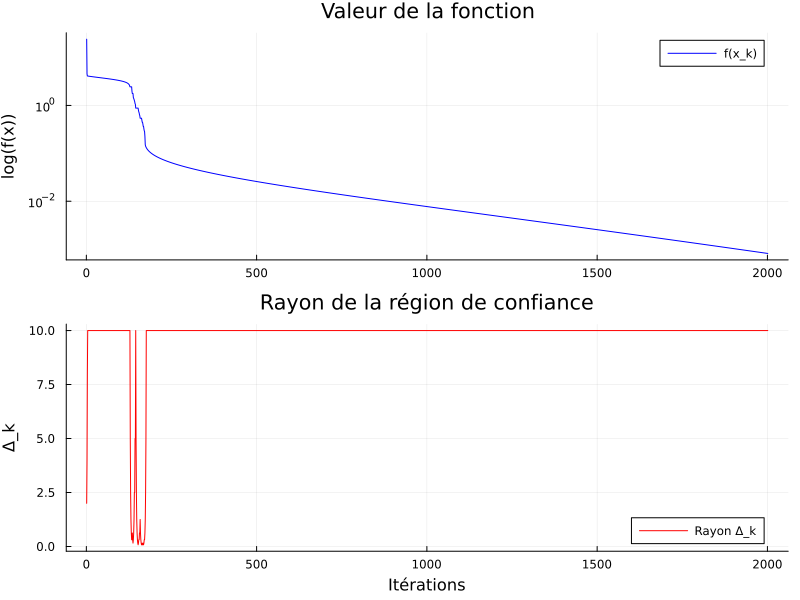

In [ ]:
# Expérimentations numériques à faire ici.
# Vous pouvez utiliser le package Plots pour les affichages de courbes: using Plots
using Plots
include("../test/fonctions_de_tests.jl")
include("../src/cauchy.jl")

function regions_de_confiance_trace(f::Function, ∇f::Function, ∇²f::Function, x0::Vector{<:Real};
    max_iter::Int=5000, tol_abs::Real=1e-10, tol_rel::Real=1e-8, δ::Real=1,
    Δ0::Real=2, Δmax::Real=10, γ1::Real=0.5, γ2::Real=2, η1::Real=0.25, η2::Real=0.75, algo_pas::String="cauchy")

    x_sol = x0
    f_sol = f(x_sol)
    flag = -1
    
    fs = [Float64(f_sol)]
    deltas = [Float64(Δ0)]

    nb_iters = 0
    Δk = Δ0

    while flag == -1
        gk = ∇f(x_sol)
        hk = ∇²f(x_sol)

        sk = cauchy(gk, hk, Δk, tol_abs=tol_abs)

        mk0 = f(x_sol)
        mksk = f(x_sol) + transpose(gk) * sk + 0.5 * transpose(sk) * hk * sk
        ρk = (f(x_sol) - f(x_sol + sk)) / (mk0 - mksk)
        
        if ρk >= η1
            x_sol = x_sol + sk
            f_sol = f(x_sol)
        end
        push!(fs, f_sol)

        if ρk >= η2
            Δk = min(γ2 * Δk, Δmax)
        elseif ρk >= η1
            # Δk inchangé
        else
            Δk = γ1 * Δk
        end
        push!(deltas, Δk)

        nb_iters += 1

        if norm(∇f(x_sol)) <= max(tol_rel * norm(∇f(x0)), tol_abs) || nb_iters >= max_iter
            flag = 0 
        end
    end
    return fs, deltas
end

# Points
x0 = pts1.x021 
fs, deltas = regions_de_confiance_trace(fct2, grad_fct2, hess_fct2, x0, algo_pas="cauchy", max_iter=2000)

# Tracé avec Plots
l = @layout [a ; b]

p1 = plot(fs, yscale=:log10, label="f(x_k)", ylabel="log(f(x))", title="Valeur de la fonction", color=:blue)
p2 = plot(deltas, label="Rayon Δ_k", xlabel="Itérations", ylabel="Δ_k", title="Rayon de la région de confiance", color=:red)

plot(p1, p2, layout=l, size=(800, 600))
display(current())



4. Lors de la minimisation de $f_2$, tracez la norme du gradient en fonction du numéro d’itération.
Discutez si la convergence semble être quadratique, et expliquez vos observations dans le cas du pas de Cauchy.

-> La convergence ne semble pas être quadratique. En effet, elle a l'air majoritairement linéaire. Puis, comme dit précédemment, le pas de Cauchy servant à trouver une direction de descente, l'algorithme suit donc un coefficient linéaire.

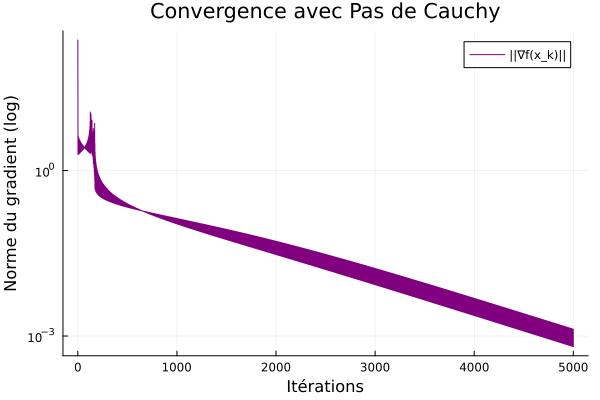

In [ ]:
# Expérimentations numériques à faire ici.
# Vous pouvez utiliser le package Plots pour les affichages de courbes: using Plots
using Plots
include("../test/fonctions_de_tests.jl")
include("../src/cauchy.jl")

function regions_de_confiance_grad(f::Function, ∇f::Function, ∇²f::Function, x0::Vector{<:Real};
    max_iter::Int=5000, tol_abs::Real=1e-10, tol_rel::Real=1e-8, δ::Real=1,
    Δ0::Real=2, Δmax::Real=10, γ1::Real=0.5, γ2::Real=2, η1::Real=0.25, η2::Real=0.75, algo_pas::String="cauchy")

    x_sol = x0
    f_sol = f(x_sol)
    flag = -1
    
    grad_norms = [norm(∇f(x0))]

    nb_iters = 0
    Δk = Δ0

    while flag == -1
        gk = ∇f(x_sol)
        hk = ∇²f(x_sol)

        sk = cauchy(gk, hk, Δk, tol_abs=tol_abs)

        mk0 = f(x_sol)
        mksk = f(x_sol) + transpose(gk) * sk + 0.5 * transpose(sk) * hk * sk
        ρk = (f(x_sol) - f(x_sol + sk)) / (mk0 - mksk)
        
        if ρk >= η1
            x_sol = x_sol + sk
        end
        push!(grad_norms, norm(∇f(x_sol)))

        if ρk >= η2
            Δk = min(γ2 * Δk, Δmax)
        elseif ρk < η1
            Δk = γ1 * Δk
        end

        nb_iters += 1
        if norm(∇f(x_sol)) <= max(tol_rel * norm(∇f(x0)), tol_abs) || nb_iters >= max_iter
            flag = 0 
        end
    end
    return grad_norms
end

# Points
x0 = pts1.x021
grad_norms = regions_de_confiance_grad(fct2, grad_fct2, hess_fct2, x0, algo_pas="cauchy", max_iter=5000)

# Tracé avec Plots
plot(0:length(grad_norms)-1, grad_norms, 
     yscale=:log10, 
     label="||∇f(x_k)||", 
     xlabel="Itérations", 
     ylabel="Norme du gradient (log)", 
     title="Convergence avec Pas de Cauchy", 
     color=:purple,
     linewidth=1)

display(current())


5. Le rayon initial de la région de confiance est un paramètre important dans l’analyse
de la performance de l’algorithme. Sur quel(s) autre(s) paramètre(s) peut-on jouer
pour essayer d’améliorer cette performance ? Étudier l’influence d’au moins deux de
ces paramètres. Pour cela vous ferez des tests numériques et donnerez les résultats sous forme de tableaux et de graphiques.

-> On peut observer dans la cellule suivante que $\Delta_max$ joue un rôle conséquent sur la convergence de l'algorithme. En effet, plus il est grand et moins le nombre d'itérations nécessaires à la convergence est grand. C'est certainement parce qu'en permettant un rayon max plus grand, on évite de faire des petits pas de Cauchy.

-> De même, les $\gamma_1$ et $\gamma_2$ sont importants puisque ce sont les facteurs par lesquels on multiplie le rayon. Selon leur proximité avec 0, on définit donc la rapidité avec laquelle on réduit ou agrandit le rayon, et donc si le devient vite minuscule ou s'il ne grandit pas assez vite.

### Étude pour le rayon maximal de la région de confiance $\Delta_{max}$

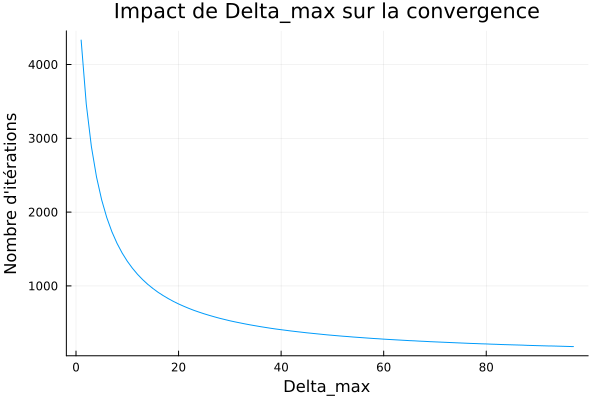

In [ ]:
# Expérimentations numériques à faire ici.
# Vous pouvez utiliser le package Plots pour les affichages de courbes: using Plots
using Plots
include("../src/regions_de_confiance.jl")
include("../test/fonctions_de_tests.jl")

x0 = [10000; 10000; 10000]
nb_iters = []

for delta_max in 1:100
    x_sol, f_sol, flag, iters = regions_de_confiance(fct1, grad_fct1, hess_fct1, x0, 
                                                       algo_pas="cauchy", Δmax=delta_max)
    if flag == 0  # Converge
        push!(nb_iters, iters)
    end
end

plot(1:length(nb_iters), nb_iters, 
     xlabel="Delta_max", 
     ylabel="Nombre d'itérations", 
     title="Impact de Delta_max sur la convergence",
     legend=false)

### Étude pour les facteurs de mise à jour de la région de confiance $\gamma_1$ et $\gamma_2$

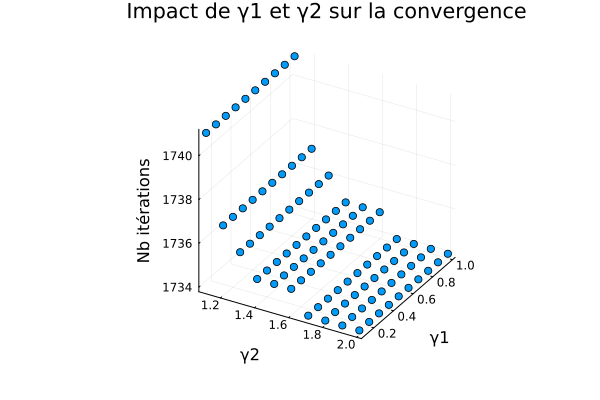

In [56]:
# Expérimentations numériques à faire ici.
# Vous pouvez utiliser le package Plots pour les affichages de courbes: using Plots
using Plots
include("../src/regions_de_confiance.jl")
include("../test/fonctions_de_tests.jl")

x0 = [10000; 10000; 10000]
gamma2_range = 1.1:0.1:2.0
gamma1_range = 0.1:0.1:1.0

nb_iters = []
gamma1_vals = []
gamma2_vals = []

for γ2 in gamma2_range
    for γ1 in gamma1_range
        x_sol, f_sol, flag, iters = regions_de_confiance(fct1, grad_fct1, hess_fct1, x0,
            algo_pas="cauchy", γ1=γ1, γ2=γ2)
        if flag == 0
            push!(nb_iters, iters)
            push!(gamma1_vals, γ1)
            push!(gamma2_vals, γ2)
        end
    end
end

scatter(gamma2_vals, gamma1_vals, nb_iters,
    xlabel="γ2",
    ylabel="γ1",
    zlabel="Nb itérations",
    title="Impact de γ1 et γ2 sur la convergence",
    marker=:circle,
    legend=false)

# Régions de confiance avec gradient conjugué tronqué

## Implémentation 

1. Implémenter l’algorithme du gradient conjugué tronqué (fichier `src/gct.jl`). Sa spécification est dans le fichier.
2. Vérifier que les tests ci-dessous passent.

In [72]:
include("../src/gct.jl")
include("../test/tester_gct.jl")

#
tester_gct(gct);

Test Summary:             | Pass  Total  Time
Gradient conjugué tronqué |    9      9  0.0s


3. Intégrer l’algorithme du gradient conjugué tronqué dans le code des régions de confiance.
4. Vérifier que les tests ci-dessous passent.

In [73]:
include("../src/regions_de_confiance.jl")
include("../test/tester_rc_gct.jl")

#
afficher = true # si true, alors affiche les résultats des algorithmes

#
tester_rc_gct(regions_de_confiance, afficher);

Affichage des résultats des algorithmes : true

-------------------------------------------------------------------------
Résultats de : RC et gct appliqué à f1:
  * x0       = [1, 0, 0]
  * x_sol    = [1.0000000000000004, 1.0000000000000002, 1.0000000000000002]
  * f(x_sol) = 1.627025617018337e-30
  * nb_iters = 1
  * flag     = 0
  * solution = [1, 1, 1]
-------------------------------------------------------------------------
Résultats de : RC et gct appliqué à f1:
  * x0       = [10.0, 3.0, -2.2]
  * x_sol    = [0.9999999999999996, 1.0000000000000004, 1.0]
  * f(x_sol) = 9.860761315262648e-31
  * nb_iters = 3
  * flag     = 0
  * solution = [1, 1, 1]
-------------------------------------------------------------------------
Résultats de : RC et gct appliqué à f2:
  * x0       = [-1.2, 1.0]
  * x_sol    = [0.999999674378009, 0.999999347837161]
  * f(x_sol) = 1.0611413032942621e-13
  * nb_iters = 31
  * flag     = 0
  * solution = [1, 1]
-----------------------------------------------

5. Considérez la minimisation de la fonction $f_2$. Tracez la norme du gradient en fonction du numéro d’itération. Discutez si la convergence semble être quadratique, et expliquez à quelle étape de l’algorithme ce comportement peut être observé et pourquoi.

-> La convergence ne semble pas être quadratique au début avec des zig-zags linéaires, avant une soudaine descente du gradient qui pourrait s'apparenter à une convergence quadratique. C'est la récupération de la convergence quadratique de la méthode de Newton comme décrite dans le sujet, qui s'expliquerait donc par la résolution exacte du modèle.

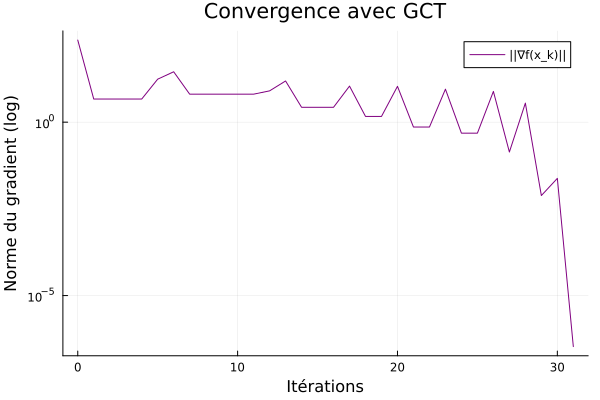

In [ ]:
# Expérimentations numériques à faire ici.
# Vous pouvez utiliser le package Plots pour les affichages de courbes: using Plots
using Plots
include("../test/fonctions_de_tests.jl")
include("../src/gct.jl")

function regions_de_confiance_grad(f::Function, ∇f::Function, ∇²f::Function, x0::Vector{<:Real};
    max_iter::Int=5000, tol_abs::Real=1e-10, tol_rel::Real=1e-8, δ::Real=1,
    Δ0::Real=2, Δmax::Real=10, γ1::Real=0.5, γ2::Real=2, η1::Real=0.25, η2::Real=0.75, algo_pas::String="gct")

    x_sol = x0
    f_sol = f(x_sol)
    flag = -1
    
    grad_norms = [norm(∇f(x0))]

    nb_iters = 0
    Δk = Δ0

    while flag == -1
        gk = ∇f(x_sol)
        hk = ∇²f(x_sol)

        sk = gct(gk, hk, Δk, tol_abs=tol_abs)

        mk0 = f(x_sol)
        mksk = f(x_sol) + transpose(gk) * sk + 0.5 * transpose(sk) * hk * sk
        ρk = (f(x_sol) - f(x_sol + sk)) / (mk0 - mksk)
        
        if ρk >= η1
            x_sol = x_sol + sk
        end
        push!(grad_norms, norm(∇f(x_sol)))

        if ρk >= η2
            Δk = min(γ2 * Δk, Δmax)
        elseif ρk < η1
            Δk = γ1 * Δk
        end

        nb_iters += 1
        if norm(∇f(x_sol)) <= max(tol_rel * norm(∇f(x0)), tol_abs) || nb_iters >= max_iter
            flag = 0 
        end
    end
    return grad_norms
end

# Points
x0 = pts1.x021
grad_norms = regions_de_confiance_grad(fct2, grad_fct2, hess_fct2, x0, algo_pas="gct", max_iter=5000)

# Tracé avec Plots
plot(0:length(grad_norms)-1, grad_norms, 
     yscale=:log10, 
     label="||∇f(x_k)||", 
     xlabel="Itérations", 
     ylabel="Norme du gradient (log)", 
     title="Convergence avec GCT", 
     color=:purple,
     linewidth=1)

display(current())


6. Lors de la minimisation de $f_2$ à l’aide de la méthode de région de confiance avec gradient conjugué tronqué, tracez à chaque itération la valeur de la fonction objectif, le rayon de la région de confiance et le type de troncature détecté. Commentez l’évolution de ces grandeurs à mesure que la méthode s’approche du minimum.

-> On observe qu'au moment où la fonction objectif diminue fortement (s'approche du minimum), le rayon de la région de confiance augmente fortement aussi, *i.e.* le pas grandit pour converger plus vite.

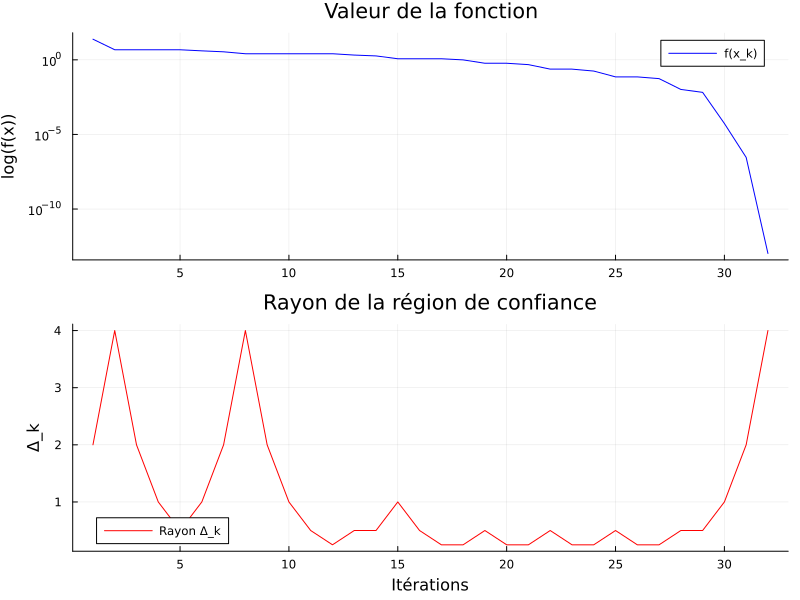

In [ ]:
# Expérimentations numériques à faire ici.
# Vous pouvez utiliser le package Plots pour les affichages de courbes: using Plots
using Plots
include("../test/fonctions_de_tests.jl")
include("../src/gct.jl")

function regions_de_confiance_trace(f::Function, ∇f::Function, ∇²f::Function, x0::Vector{<:Real};
    max_iter::Int=5000, tol_abs::Real=1e-10, tol_rel::Real=1e-8, δ::Real=1,
    Δ0::Real=2, Δmax::Real=10, γ1::Real=0.5, γ2::Real=2, η1::Real=0.25, η2::Real=0.75, algo_pas::String="gct")

    x_sol = x0
    f_sol = f(x_sol)
    flag = -1
    
    fs = [Float64(f_sol)]
    deltas = [Float64(Δ0)]

    nb_iters = 0
    Δk = Δ0

    while flag == -1
        gk = ∇f(x_sol)
        hk = ∇²f(x_sol)

        # Calcul GCT
        sk = gct(gk, hk, Δk, tol_abs=tol_abs)

        mk0 = f(x_sol)
        mksk = f(x_sol) + transpose(gk) * sk + 0.5 * transpose(sk) * hk * sk
        ρk = (f(x_sol) - f(x_sol + sk)) / (mk0 - mksk)
        
        if ρk >= η1
            x_sol = x_sol + sk
            f_sol = f(x_sol)
        end
        push!(fs, f_sol)

        # Mise à jour du rayon
        if ρk >= η2
            Δk = min(γ2 * Δk, Δmax)
        elseif ρk >= η1
            # Δk inchangé
        else
            Δk = γ1 * Δk
        end
        push!(deltas, Δk)

        nb_iters += 1

        if norm(∇f(x_sol)) <= max(tol_rel * norm(∇f(x0)), tol_abs) || nb_iters >= max_iter
            flag = 0 
        end
    end
    return fs, deltas
end

# Points
x0 = pts1.x021 
fs, deltas = regions_de_confiance_trace(fct2, grad_fct2, hess_fct2, x0, algo_pas="gct", max_iter=2000)

#Tracé avec Plots
l = @layout [a ; b]

p1 = plot(fs, yscale=:log10, label="f(x_k)", ylabel="log(f(x))", title="Valeur de la fonction", color=:blue)
p2 = plot(deltas, label="Rayon Δ_k", xlabel="Itérations", ylabel="Δ_k", title="Rayon de la région de confiance", color=:red)

plot(p1, p2, layout=l, size=(800, 600))
display(current())


7. Minimisez $f_1$ à l’aide de la méthode de région de confiance avec gradient conjugué tronqué, en partant d’un rayon initial de région de confiance $\Delta_0 = 10^9$. Comparez ses performances à celles de la méthode de Newton. Expliquez vos observations.

-> Les deux algorithmes convergent en 1 itération. Cela peut encore s'expliquer par le développement de Taylor à l'ordre 2 de $f_1$ qui est exact et qui permet donc au GCT avec un aussi grand rayon de directement résoudre le problème comme l'algorithme de Newton.

In [74]:
# Expérimentations numériques à faire ici.
# Vous pouvez utiliser le package Plots pour les affichages de courbes
using Plots
include("../src/newton.jl")
include("../src/regions_de_confiance.jl")
include("../test/fonctions_de_tests.jl")

x0 = pts1.x011

# GCT avec Δ0 = 10e9
x_sol_gct, f_sol_gct, flag_gct, nb_iters_gct, xs_gct = regions_de_confiance(
    fct1, grad_fct1, hess_fct1, x0, 
    algo_pas="gct", Δ0=1e9, Δmax=1e10)

# Newton
x_sol_newton, f_sol_newton, flag_newton, nb_iters_newton, xs_newton = newton(
    fct1, grad_fct1, hess_fct1, x0)

# Affichage des résultats
println("Comparaison RC-GCT et Newton sur f1n")
afficher_resultats("RC-GCT (Δ0=10⁹)", "f1", x0, x_sol_gct, f_sol_gct, flag_gct, nb_iters_gct, sol_exacte_fct1)
afficher_resultats("Newton", "f1", x0, x_sol_newton, f_sol_newton, flag_newton, nb_iters_newton, sol_exacte_fct1)

Comparaison RC-GCT et Newton sur f1n
-------------------------------------------------------------------------
Résultats de : RC-GCT (Δ0=10⁹) appliqué à f1:
  * x0       = [1, 0, 0]
  * x_sol    = [1.0000000000000004, 1.0000000000000002, 1.0000000000000002]
  * f(x_sol) = 1.627025617018337e-30
  * nb_iters = 1
  * flag     = 0
  * solution = [1, 1, 1]
-------------------------------------------------------------------------
Résultats de : Newton appliqué à f1:
  * x0       = [1, 0, 0]
  * x_sol    = [1.0, 1.0, 0.9999999999999999]
  * f(x_sol) = 1.232595164407831e-32
  * nb_iters = 1
  * flag     = 0
  * solution = [1, 1, 1]


## Interprétation  

Nous proposons de comparer l'utilisation du pas de Cauchy avec celle du gradient conjugué tronqué dans l'algorithme des régions de confiance.

**Remarques.**
* Nous vous demandons de réaliser des expérimentations numériques pour les comparaisons demandées ci-après.
* Vous devez utiliser l'argument optionnel `max_iter_gct` et la sortie `xs` de l'algorithme des régions de confiance.
* Vous pouvez comparer l'écart en norme entre les itérés de l'algorithme et la solution du problème.
* Vous trouverez des choses utiles dans le fichier `test/fonctions_de_tests.jl`.

1. Comparer dans le cas où l'on force le gradient conjugué tronqué à ne faire qu'une seule itération. Que remarquez vous ?

-> (commenter la ligne de plotting du gct normal pour le voir) On remarque que le GCT en une itération est très proche du Pas de Cauchy.
2. Comparer dans le cas général. Que remarquez vous ?

-> Dans le cas général, le GCT converge drastiquement plus vite que le Pas de Cauchy, probablement grâce aux différentes directions offertes par les gradients conjugués.
3. Quels sont les avantages et inconvénients des deux approches ?

-> Le pas de Cauchy est plus simple à implémenter et moins coûteux en caclculs, mais converge lentement et peut vite demander beaucoup d'itérations pour converger.

Les régions de confiance avec GCT converge bien plus rapidement, mais est plus compliqué à implémenter et est plus coûteux en calculs.

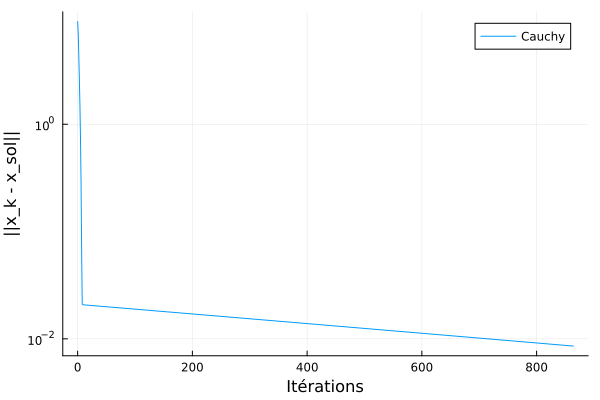


Comparaison Cauchy vs GCT sur f2

-------------------------------------------------------------------------
Résultats de : Cauchy appliqué à f2:
  * x0       = [10, 0]
  * x_sol    = [0.9961677295959247, 0.9923393628794702]
  * f(x_sol) = 1.4697922915267688e-5
  * nb_iters = 864
  * flag     = 0
  * solution = [1, 1]
-------------------------------------------------------------------------
Résultats de : GCT (1 iter) appliqué à f2:
  * x0       = [10, 0]
  * x_sol    = [0.9961677295964368, 0.9923393628804894]
  * f(x_sol) = 1.4697922911344958e-5
  * nb_iters = 864
  * flag     = 0
  * solution = [1, 1]
-------------------------------------------------------------------------
Résultats de : GCT (normal) appliqué à f2:
  * x0       = [10, 0]
  * x_sol    = [1.000003518300986, 1.0000066949336195]
  * f(x_sol) = 2.4053014040534547e-11
  * nb_iters = 44
  * flag     = 0
  * solution = [1, 1]


In [84]:
# Expérimentations numériques à faire ici.
# Vous pouvez utiliser le package Plots pour les affichages de courbes: using Plots
using Plots
include("../src/regions_de_confiance.jl")
include("../test/fonctions_de_tests.jl")

# Point initial
x0 = pts1.x022

# Pas de Cauchy
x_sol_cauchy, f_sol_cauchy, flag_cauchy, nb_iters_cauchy, xs_cauchy = regions_de_confiance(
    fct2, grad_fct2, hess_fct2, x0, algo_pas="cauchy")
err_cauchy = [norm(x - sol_exacte_fct2) for x in xs_cauchy]
plot(0:nb_iters_cauchy, err_cauchy, xlabel="Itérations", ylabel="||x_k - x_sol||", label="Cauchy", yscale=:log10)

# GCT avec une seule itération
x_sol_gct1, f_sol_gct1, flag_gct1, nb_iters_gct1, xs_gct1 = regions_de_confiance(
    fct2, grad_fct2, hess_fct2, x0, algo_pas="gct", max_iter_gct=1)
err_gct1 = [norm(x - sol_exacte_fct2) for x in xs_gct1]
plot!(0:nb_iters_gct1, err_gct1, label="GCT (1 iter)")

# GCT normal
x_sol_gct, f_sol_gct, flag_gct, nb_iters_gct, xs_gct = regions_de_confiance(
    fct2, grad_fct2, hess_fct2, x0, algo_pas="gct")
err_gct = [norm(x - sol_exacte_fct2) for x in xs_gct]
plot!(0:nb_iters_gct, err_gct, label="GCT (normal)", title="Convergence vers la solution")

display(current())

# Affichage
println("\nComparaison Cauchy vs GCT sur f2\n")
afficher_resultats("Cauchy", "f2", x0, x_sol_cauchy, f_sol_cauchy, flag_cauchy, nb_iters_cauchy, sol_exacte_fct2)
afficher_resultats("GCT (1 iter)", "f2", x0, x_sol_gct1, f_sol_gct1, flag_gct1, nb_iters_gct1, sol_exacte_fct2)
afficher_resultats("GCT (normal)", "f2", x0, x_sol_gct, f_sol_gct, flag_gct, nb_iters_gct, sol_exacte_fct2)